# Frente B, capítulo 3: ondas lentas y promediado de Woody (etapa 7)

**Módulos:** `descriptores/ondas_lentas.py`, `descriptores/woody.py` · **Figuras:** `b_ondas_*`, `b_woody_*`

## De qué se trata

Las **ondas lentas** son la marca de N3, el sueño profundo: ondas de menos de 4 Hz y de
gran amplitud, que se ven mejor en los electrodos frontales. El manual AASM define N3
por la presencia de estas ondas, así que se detectan una por una y se cuentan.

Además, cada paciente tiene una **forma típica** de onda lenta. Para estimarla se
promedian todas sus ondas, y ahí aparece un problema que resuelve el promediado de
Woody (técnica no vista en clase): las ondas no están bien alineadas entre sí.

## El recorrido de la señal

```
EEG frontal (F4), toda la noche
   │
   ├─ pasa-banda de 0,2 a 4 Hz, sin desfase                  _filtrar()
   ├─ se recorre onda por onda, entre cruces por cero         _buscar_ondas()
   ├─ se queda con las que cumplen el criterio de amplitud
   │
   ├─ se recorta 1 s antes y 1 s después de cada pico
   ├─ promediado de Woody: forma típica del paciente          promediado_woody()
   ├─ parecido de cada onda con esa forma                     similitud_con_plantilla()
   │
   └─ por época: cantidad, amplitud media y parecido medio    descriptores_ondas_lentas()
```

## Entorno y datos

Los resultados de abajo se calcularon con un registro real de la base (el primero que
haya descargado, en orden). Si no hay datos descargados, el notebook usa el registro
sintético de `comun/sintetico.py` y las figuras cambian. Mientras el Frente A no esté
implementado, las señales llegan **crudas**: sin filtrar y sin quitar los artefactos.

In [1]:
# Entorno común a todos los notebooks: se corre desde codigo/ para que DIR_DATOS
# ("data" o $ESTADIOS_DATOS) apunte al mismo lugar que los scripts.
import os
import sys
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

# Si el paquete no está instalado con `pip install -e .`, se usa directamente codigo/src.
# Las dependencias (numpy, scipy, pandas, matplotlib, mne) sí tienen que estar
# instaladas en el Python de este kernel.
try:
    import estadios  # noqa: F401
except ModuleNotFoundError:
    sys.path.insert(0, str(Path.cwd() / "src"))
FIGURAS = Path.cwd().parent / "informe" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt

from estadios.comun.config import Config
from estadios.comun.constantes import NOMBRES_ESTADIOS, N_ESTADIOS
from estadios.datos.carga import ids_disponibles

USAR_DATOS_REALES = len(ids_disponibles()) > 0
print("Datos reales" if USAR_DATOS_REALES else "Sin datos descargados: se usan los sintéticos")

Datos reales


In [2]:
# Estilo común de las figuras del Frente B. Cada estadio tiene siempre el mismo color.
COLOR_ESTADIO = dict(zip(NOMBRES_ESTADIOS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
AZUL, NARANJA, VERDE = "#2a78d6", "#eb6834", "#1baf7a"
GRIS, TINTA = "#8a8984", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRIS,
    "axes.labelcolor": TINTA,
    "axes.titlesize": 10,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "xtick.color": TINTA,
    "ytick.color": TINTA,
    "lines.linewidth": 1.5,
    "legend.frameon": False,
})


def guardar(fig, nombre):
    """Guarda la figura en informe/figuras/ para incluirla con \\includegraphics."""
    fig.savefig(FIGURAS / f"{nombre}.pdf", bbox_inches="tight")


def por_estadio(ax, valores, estadios, titulo, unidad=""):
    """Diagrama de caja de un descriptor en cada estadio, sin los valores extremos."""
    grupos = [valores[estadios == e] for e in range(N_ESTADIOS)]
    cajas = ax.boxplot(grupos, tick_labels=NOMBRES_ESTADIOS, showfliers=False,
                       patch_artist=True, widths=0.55,
                       medianprops={"color": TINTA, "linewidth": 1.5})
    for caja, nombre in zip(cajas["boxes"], NOMBRES_ESTADIOS):
        caja.set(facecolor=COLOR_ESTADIO[nombre], alpha=0.55, edgecolor=GRIS)
    ax.set(title=titulo, ylabel=unidad)
    ax.grid(axis="x", visible=False)

In [3]:
from estadios.comun.contratos import RegistroPreprocesado
from estadios.comun.sintetico import preprocesado_sintetico
from estadios.datos.carga import cargar_registro
from estadios.pipeline import preprocesar

cfg = Config().descriptores
if USAR_DATOS_REALES:
    crudo = cargar_registro(ids_disponibles()[0])
    try:
        prep = preprocesar(crudo, Config().preprocesamiento)
    except NotImplementedError:
        # Mientras el Frente A no esté, se trabaja sobre la señal cruda. Las funciones
        # del Frente B filtran por su cuenta en la banda que les interesa.
        print("El Frente A todavía no está: se usa la señal cruda.")
        prep = RegistroPreprocesado(
            crudo,
            latidos=np.array([], dtype=int),
            no_estacionaria=np.zeros(crudo.n_epocas, dtype=bool),
        )
else:
    prep = preprocesado_sintetico(minutos=120)

registro = prep.registro
fs = registro.fs
estadios_tecnicos = registro.estadios
print(f"{registro.id}: {registro.n_epocas} épocas de 30 s ({registro.n_epocas / 120:.1f} h)")
print({n: int((estadios_tecnicos == e).sum()) for e, n in enumerate(NOMBRES_ESTADIOS)})

El Frente A todavía no está: se usa la señal cruda.
SN122: 845 épocas de 30 s (7.0 h)
{'W': 66, 'N1': 67, 'N2': 303, 'N3': 288, 'R': 121}


## 1. Detección: el criterio visto en clase

La señal se filtra entre 0,2 y 4 Hz (Butterworth de orden 2, aplicado hacia adelante y
hacia atrás para no desplazarla). Después se la recorre **onda por onda**: cada onda
empieza cuando la señal cruza el cero bajando y termina en el siguiente cruce
descendente, así que tiene una fase negativa seguida de una positiva.

Una onda se acepta como onda lenta si cumple las dos condiciones de Piantoni et al.:

- su pico negativo es menor a **−60 µV**;
- su amplitud pico a pico (del pico negativo al máximo de la fase positiva) es de al
  menos **75 µV**.

La figura muestra 20 s de N3 con las ondas detectadas.

Ondas lentas detectadas en la noche: 1542


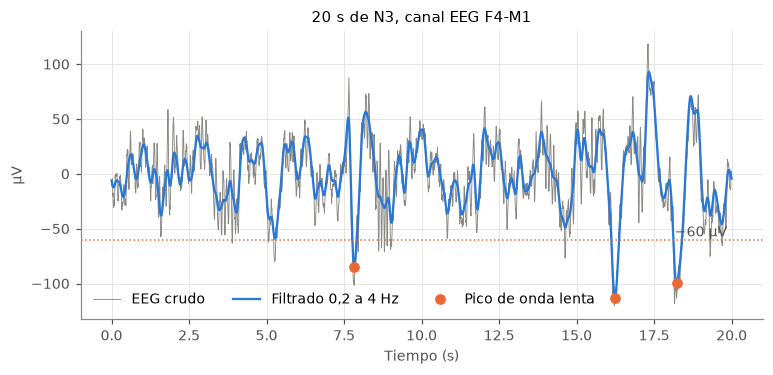

In [4]:
from estadios.comun.constantes import N3
from estadios.descriptores import ondas_lentas, woody

f4 = registro.senales[cfg.canal_ondas]
filtrada = ondas_lentas._filtrar(f4, fs, cfg.ondas_banda_hz)
picos, amplitudes = ondas_lentas._buscar_ondas(filtrada, cfg.ondas_pico_uv, cfg.ondas_pico_a_pico_uv)

n_epoca = int(30 * fs)
epocas_n3 = np.flatnonzero(estadios_tecnicos == N3)
inicio = epocas_n3[len(epocas_n3) // 2] * n_epoca if len(epocas_n3) else 0
ventana = slice(inicio, inicio + int(20 * fs))
t = np.arange(ventana.start, ventana.stop) / fs - inicio / fs
en_ventana = picos[(picos >= ventana.start) & (picos < ventana.stop)]

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(t, f4[ventana], color=GRIS, lw=0.6, label="EEG crudo")
ax.plot(t, filtrada[ventana], color=AZUL, label="Filtrado 0,2 a 4 Hz")
ax.plot((en_ventana - inicio) / fs, filtrada[en_ventana], "o", color=NARANJA, ms=6, label="Pico de onda lenta")
ax.axhline(cfg.ondas_pico_uv, color=NARANJA, ls=":", lw=1)
ax.text(t[-1], cfg.ondas_pico_uv, "−60 µV ", ha="right", va="bottom", color=TINTA)
ax.set(xlabel="Tiempo (s)", ylabel="µV", title=f"20 s de N3, canal {cfg.canal_ondas}")
ax.legend(loc="lower left", ncols=3)
guardar(fig, "b_ondas_deteccion")
print(f"Ondas lentas detectadas en la noche: {len(picos)}")

En N3 las ondas lentas aparecen una tras otra, y casi todos los valles grandes superan
el umbral. Las más chicas quedan afuera por el criterio de amplitud.

### Cuántas hay en cada estadio

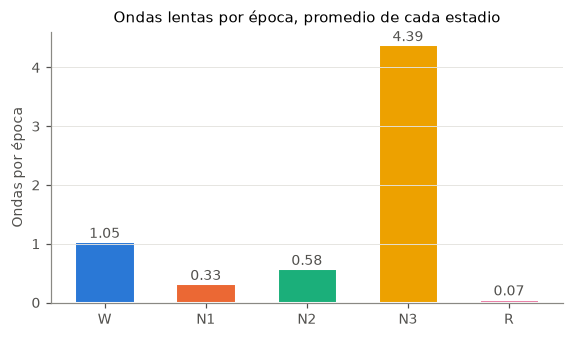

In [5]:
matriz, nombres = ondas_lentas.descriptores_ondas_lentas(prep, cfg)
cantidad = matriz[:, nombres.index("ondas.cantidad")]

fig, ax = plt.subplots(figsize=(6, 3.2))
medias = [cantidad[estadios_tecnicos == e].mean() if (estadios_tecnicos == e).any() else 0 for e in range(N_ESTADIOS)]
ax.bar(NOMBRES_ESTADIOS, medias, color=[COLOR_ESTADIO[n] for n in NOMBRES_ESTADIOS], width=0.6, edgecolor="white", linewidth=2)
for x, m in enumerate(medias):
    ax.text(x, m, f"{m:.2f}", ha="center", va="bottom", color=TINTA)
ax.set(title="Ondas lentas por época, promedio de cada estadio", ylabel="Ondas por época")
ax.grid(axis="x", visible=False)
guardar(fig, "b_ondas_por_estadio")

N3 tiene varias ondas lentas por época y el resto muy pocas.

**Ondas lentas en vigilia (W), sin el artefacto ocular.** Se completará cuando se complete A.

Hay una decisión abierta en el README que afecta este capítulo: el pasa-altos del
Frente A está en 0,5 Hz y este detector trabaja desde 0,2 Hz, así que la parte de 0,2 a
0,5 Hz no va a llegar cuando se use la señal preprocesada.

## 2. El problema de promediar ondas desalineadas

Para conocer la forma típica de las ondas lentas del paciente, se recorta cada onda
desde 1 s antes hasta 1 s después de su pico y se promedian. Pero el pico detectado no
cae siempre en el mismo punto de la onda: el ruido lo corre unas decenas de
milisegundos. Al promediar ondas corridas entre sí, los valles no coinciden y el
promedio resulta **más ancho y más chico** que una onda real.

## 3. El promediado de Woody

Woody (1967) corrige esto en un proceso iterativo.

1. Se arranca con el promedio ordinario como plantilla.
2. Para cada onda se busca el corrimiento, de hasta ±0,25 s, que la hace parecerse más
   a la plantilla. El parecido se mide con la correlación cruzada, calculada con la FFT
   para probar todos los corrimientos de una vez.
3. Se corre cada onda según su corrimiento y se recalcula el promedio, que ahora es de
   ondas alineadas.
4. Se repiten los pasos 2 y 3 hasta que los corrimientos dejan de cambiar.

Al correr una onda, uno de sus extremos queda sin datos: esas muestras se marcan como
faltantes (`NaN`) y el promedio de cada instante usa solo las ondas que tienen dato
ahí.

Iteraciones: 20 (el máximo es 20).
Ondas con el corrimiento máximo permitido (±250 ms): 28 de 1542.
Valle del promedio ordinario: -86.8 µV. Valle de la plantilla de Woody: -77.8 µV.
Fase positiva del promedio ordinario: 33.1 µV. De la plantilla de Woody: 39.4 µV.


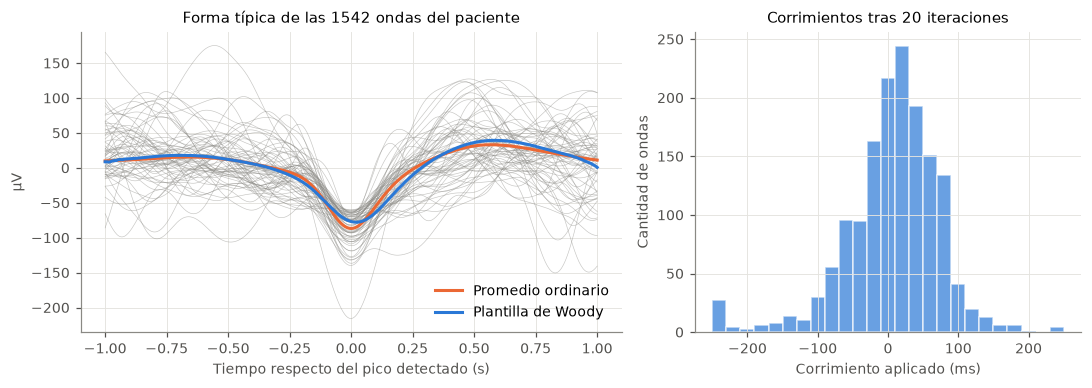

In [6]:
mitad = int(ondas_lentas.VENTANA_ONDA_S * fs)
recortables = picos[(picos >= mitad) & (picos + mitad < len(filtrada))]
realizaciones = np.stack([filtrada[p - mitad : p + mitad + 1] for p in recortables])
resultado = woody.promediado_woody(realizaciones, int(ondas_lentas.MAX_DESPLAZAMIENTO_S * fs))
ordinario = realizaciones.mean(axis=0)
t = np.arange(-mitad, mitad + 1) / fs

fig, axs = plt.subplots(1, 2, figsize=(10, 3.6), width_ratios=[1.4, 1])
for onda in realizaciones[:: max(1, len(realizaciones) // 60)]:
    axs[0].plot(t, onda, color=GRIS, lw=0.4, alpha=0.5)
axs[0].plot(t, ordinario, color=NARANJA, lw=2, label="Promedio ordinario")
axs[0].plot(t, resultado.plantilla, color=AZUL, lw=2, label="Plantilla de Woody")
axs[0].set(xlabel="Tiempo respecto del pico detectado (s)", ylabel="µV",
           title=f"Forma típica de las {len(realizaciones)} ondas del paciente")
axs[0].legend(loc="lower right")
axs[1].hist(resultado.desplazamientos / fs * 1000, bins=25, color=AZUL, alpha=0.7, edgecolor="white")
axs[1].set(xlabel="Corrimiento aplicado (ms)", ylabel="Cantidad de ondas",
           title=f"Corrimientos tras {resultado.n_iteraciones} iteraciones")
fig.tight_layout()
guardar(fig, "b_woody_plantilla")

en_el_limite = np.abs(resultado.desplazamientos) >= int(ondas_lentas.MAX_DESPLAZAMIENTO_S * fs)
print(f"Iteraciones: {resultado.n_iteraciones} (el máximo es 20).")
print(f"Ondas con el corrimiento máximo permitido (±250 ms): {en_el_limite.sum()} de {len(realizaciones)}.")
print(f"Valle del promedio ordinario: {ordinario.min():.1f} µV. Valle de la plantilla de Woody: {np.nanmin(resultado.plantilla):.1f} µV.")
print(f"Fase positiva del promedio ordinario: {ordinario.max():.1f} µV. De la plantilla de Woody: {np.nanmax(resultado.plantilla):.1f} µV.")

Las líneas grises son algunas de las ondas recortadas, y se ve cuánto varían entre sí.
El resultado tiene un detalle que conviene entender.

En este registro el promedio ordinario tiene un valle **más profundo** que la plantilla
de Woody. Esto pasa porque cada onda se recortó centrada en su propio pico detectado,
que es justamente el mínimo de la señal filtrada: el promedio ordinario ya tiene todos
los valles perfectamente alineados, y además suma el ruido que hace más profundo cada
mínimo. Woody, en cambio, no alinea un punto sino **la onda completa**, con su fase
negativa y su fase positiva. Por eso su valle queda algo menos profundo, y su fase
positiva (cerca de +0,5 s) queda un poco más alta y mejor definida.

El histograma muestra cuánto hubo que mover cada onda. La mayoría se corrió menos de
100 ms. Unas pocas llegaron al límite de ±250 ms, y el proceso alcanzó el máximo de 20
iteraciones sin que los corrimientos dejaran de cambiar del todo: son ondas muy
deformadas, que no se parecen bien a la plantilla en ninguna posición y van saltando de
un corrimiento a otro.

Cuál de las dos formas es **más fiel** a la onda real es la hipótesis H2, y acá no se
puede responder, porque no se conoce la forma verdadera de estas ondas. Por eso H2 se
prueba en el notebook 04 con ondas de forma conocida, insertadas en EEG de vigilia con
corrimientos al azar.

## 4. Cuánto se parece cada onda a la forma típica

`similitud_con_plantilla()` calcula la correlación de cada onda, ya alineada, con la
plantilla: vale 1 si tienen la misma forma y 0 si no se parecen. Una onda lenta
genuina se parece a la plantilla, mientras que un artefacto con amplitud suficiente
para pasar el umbral suele tener otra forma.

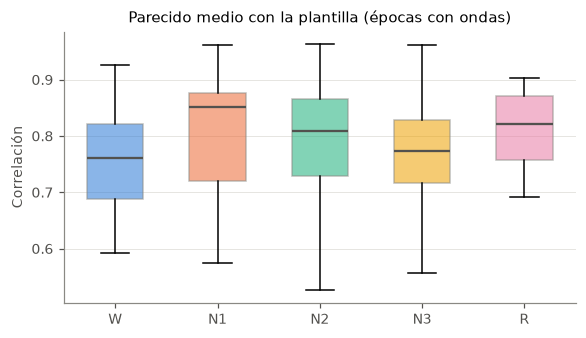

In [7]:
similitud = matriz[:, nombres.index("ondas.similitud")]
con_ondas = cantidad > 0

fig, ax = plt.subplots(figsize=(6, 3.2))
por_estadio(ax, np.where(con_ondas, similitud, np.nan), np.where(con_ondas, estadios_tecnicos, -1),
            "Parecido medio con la plantilla (épocas con ondas)", "Correlación")
guardar(fig, "b_woody_similitud")

## 5. Lo que sale de este capítulo

Tres descriptores por época: `ondas.cantidad`, `ondas.amplitud` (pico a pico medio) y
`ondas.similitud`. Una época sin ondas lentas vale 0 en los tres. Las ondas pegadas al
principio o al final de la noche cuentan, pero no tienen ventana completa para
calcular su parecido.